## 1. Loading Morphological Data

We load the morphological measurements, species names, and specimen identifiers from the provided RData file. We also inspect the dataset structure and check for missing values.

In [1]:
from pathlib import Path

# Paths
DATA_DIR = Path("../data/images")

ORIGINAL_DIR = DATA_DIR / "original"
MASK_DIR = DATA_DIR / "mask"

# Load image paths
images = sorted(ORIGINAL_DIR.glob("*.jpg"))
masks = sorted(MASK_DIR.glob("*.png"))

print(f"Original images: {len(images)}")
print(f"Masks: {len(masks)}")

# Match files by name (without extension)
image_names = {img.stem for img in images}
mask_names = {mask.stem for mask in masks}

matched = image_names & mask_names
missing_masks = image_names - mask_names
missing_images = mask_names - image_names

print(f"\nMatched pairs: {len(matched)}")
print(f"Images without masks: {len(missing_masks)}")
print(f"Masks without images: {len(missing_images)}")

# Show examples
print("\nExample matched pairs:")
for name in sorted(matched)[:5]:
    print(f"{name}.jpg <-> {name}.png")

# Show missing files
if missing_masks:
    print("\nImages without masks:")
    print(sorted(missing_masks)[:10])

if missing_images:
    print("\nMasks without images:")
    print(sorted(missing_images)[:10])


Original images: 3542
Masks: 3542

Matched pairs: 3542
Images without masks: 0
Masks without images: 0

Example matched pairs:
anic32-015672-1_p_1.jpg <-> anic32-015672-1_p_1.png
anic32-015689-1_p_1.jpg <-> anic32-015689-1_p_1.png
anic32-032237-1_p_1.jpg <-> anic32-032237-1_p_1.png
anic32-043297_p_1.jpg <-> anic32-043297_p_1.png
anic32-046417_p_1.jpg <-> anic32-046417_p_1.png


In [2]:
import pyreadr

# Paths
DATA_DIR = Path("../data")
RDATA_PATH = DATA_DIR / "mor_dig.RData"

# Load R data

data = pyreadr.read_r(str(RDATA_PATH))

# Explore available objects
print("Available objects:")
print(list(data.keys()))

for name, df in data.items():
    print(f"\n{'=' * 40}")
    print(f"Object: {name}")
    print(f"Shape: {df.shape}")

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    print(df.head())

    print("\nMissing values:")
    print(df.isna().sum())


Available objects:
['mor_dig', 'spe', 'ant']

Object: mor_dig
Shape: (3542, 4)

Columns:
['TL', 'HL', 'EL', 'WL']

First 5 rows:
     TL    HL    EL    WL
0  4.07  0.83  0.13  0.95
1  5.37  0.85  0.20  1.36
2  6.26  2.32  0.21  0.82
3  5.33  1.64  0.14  0.67
4  5.10  0.96  0.20  1.31

Missing values:
TL    0
HL    0
EL    0
WL    0
dtype: int64

Object: spe
Shape: (3542, 1)

Columns:
['spe']

First 5 rows:
                          spe
0  Acanthomyrmex careoscrobis
1  Acanthomyrmex crassispinus
2         Acanthomyrmex dusun
3       Acanthomyrmex humilis
4        Acanthomyrmex laevis

Missing values:
spe    0
dtype: int64

Object: ant
Shape: (3542, 1)

Columns:
['ant']

First 5 rows:
             ant
0  casent0901703
1  casent0101994
2  casent0281793
3  casent0911123
4  casent0281792

Missing values:
ant    0
dtype: int64


## 2. Building the Dataset

We combine specimen identifiers, species names, and morphological measurements into a single DataFrame. Each specimen is then linked to its original JPG image and corresponding PNG segmentation mask.

In [3]:
import pyreadr
import pandas as pd


# Project paths
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
OUTPUT_DIR = DATA_DIR / "processed"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load RData
data = pyreadr.read_r(str(DATA_DIR / "mor_dig.RData"))

# Combine measurements, species and specimen IDs
df = pd.concat(
    [
        data["ant"].reset_index(drop=True),
        data["spe"].reset_index(drop=True),
        data["mor_dig"].reset_index(drop=True),
    ],
    axis=1,
)

# Rename columns
df = df.rename(
    columns={
        "ant": "specimen_id",
        "spe": "species",
    }
)

# Create image and mask paths
df["image_path"] = df["specimen_id"].apply(
    lambda name: f"data/images/original/{name}_p_1.jpg"
)

df["mask_path"] = df["specimen_id"].apply(
    lambda name: f"data/images/mask/{name}_p_1.png"
)

# Check that files exist
df["image_exists"] = df["image_path"].apply(
    lambda path: (ROOT / path).is_file()
)

df["mask_exists"] = df["mask_path"].apply(
    lambda path: (ROOT / path).is_file()
)

# Dataset validation
print(f"Total specimens: {len(df)}")
print(f"Unique specimens: {df['specimen_id'].nunique()}")
print(f"Images found: {df['image_exists'].sum()}")
print(f"Masks found: {df['mask_exists'].sum()}")

print("\nMissing values:")
print(df.isna().sum())

print("\nFirst 5 rows:")
print(df.head().to_string(index=False))

# Save only when every image and mask is found
if df["image_exists"].all() and df["mask_exists"].all():
    df = df.drop(columns=["image_exists", "mask_exists"])

    output_path = OUTPUT_DIR / "dataset.csv"
    df.to_csv(output_path, index=False)

    print(f"\nDataset saved to: {output_path}")
else:
    print("\nWARNING: Some images or masks are missing!")
    print(
        df.loc[
            ~df["image_exists"] | ~df["mask_exists"],
            ["specimen_id", "image_path", "mask_path"],
        ].head(10).to_string(index=False)
    )


Total specimens: 3542
Unique specimens: 3542
Images found: 3542
Masks found: 3542

Missing values:
specimen_id     0
species         0
TL              0
HL              0
EL              0
WL              0
image_path      0
mask_path       0
image_exists    0
mask_exists     0
dtype: int64

First 5 rows:
  specimen_id                    species   TL   HL   EL   WL                                 image_path                              mask_path  image_exists  mask_exists
casent0901703 Acanthomyrmex careoscrobis 4.07 0.83 0.13 0.95 data/images/original/casent0901703_p_1.jpg data/images/mask/casent0901703_p_1.png          True         True
casent0101994 Acanthomyrmex crassispinus 5.37 0.85 0.20 1.36 data/images/original/casent0101994_p_1.jpg data/images/mask/casent0101994_p_1.png          True         True
casent0281793        Acanthomyrmex dusun 6.26 2.32 0.21 0.82 data/images/original/casent0281793_p_1.jpg data/images/mask/casent0281793_p_1.png          True         True
casent0911123


## Converting Pixel Measurements to Millimeters (Calculuuuss)

column of the .txt : "scale" "X1_scale" "X2_scale" "Y1_scale" "Y2_scale" "X1_WL" "X2_WL" "Y1_WL" "Y2_WL"

So for each image:
- **Weber's length landmarks:** two points marking the endpoints of the thorax measurement.
- **Scale bar landmarks:** two points marking the endpoints of the scale bar, whose real-world length is known.

Since the coordinates are expressed in pixels, we first calculate the Euclidean distance between the two Weber's length landmarks:

$$
d_{WL} = \sqrt{(X_{2,WL}-X_{1,WL})^2 + (Y_{2,WL}-Y_{1,WL})^2}
$$

Similarly, we calculate the length of the scale bar in pixels:

$$
d_{scale} = \sqrt{(X_{2,scale}-X_{1,scale})^2 + (Y_{2,scale}-Y_{1,scale})^2}
$$

To convert Weber's length from pixels to millimeters, we use the ratio between the known physical length of the scale bar and its measured pixel length:

$$
WL_{manual} = d_{WL} \times \frac{scale}{d_{scale}}
$$

Where:
- $d_{WL}$ is Weber's length in pixels.
- $d_{scale}$ is the scale bar length in pixels.
- $scale$ is the known physical length of the scale bar in millimeters.
- $WL_{manual}$ is the resulting Weber's length in millimeters.

This conversion accounts for differences in image magnification, allowing morphological measurements to be compared across specimens.


## 3. Processing Manual Annotations

We load the 500 manually annotated specimens and compute Weber's length in pixels using the provided landmarks. The scale bar is used to convert these measurements into millimeters.

In [4]:

import numpy as np
import pandas as pd

# Load manual annotations
annotations = pd.read_csv(
    DATA_DIR / "WL_digitalized.txt",
    sep=r"\s+",
    index_col=0
)

# Recover image filenames and specimen IDs
annotations.index.name = "image_filename"
annotations = annotations.reset_index()

annotations["specimen_id"] = (
    annotations["image_filename"]
    .str.replace(r"_p_1\.jpg$", "", regex=True)
)

# Calculate scale bar length in pixels
annotations["scale_px"] = np.hypot(
    annotations["X2_scale"] - annotations["X1_scale"],
    annotations["Y2_scale"] - annotations["Y1_scale"]
)

# Calculate Weber's length in pixels
annotations["WL_px"] = np.hypot(
    annotations["X2_WL"] - annotations["X1_WL"],
    annotations["Y2_WL"] - annotations["Y1_WL"]
)

# Convert WL to millimeters
annotations["WL_manual_mm"] = (
    annotations["WL_px"]
    / annotations["scale_px"]
    * annotations["scale"]
)

print(f"Manual annotations: {len(annotations)}")

print("\nFirst 5 measurements:")
print(
    annotations[
        ["specimen_id", "scale_px", "WL_px", "WL_manual_mm"]
    ].head()
)

print("\nWL statistics (mm):")
print(annotations["WL_manual_mm"].describe())


Manual annotations: 500

First 5 measurements:
       specimen_id    scale_px       WL_px  WL_manual_mm
0  anic32-015672-1  393.017661  409.877172      0.521449
1  anic32-015689-1  477.190690  583.778345      0.611682
2  anic32-032237-1  148.888206  383.164655      1.286753
3    anic32-043297  212.912951  496.642105      2.332606
4    anic32-046417  204.397597  594.262625      2.907386

WL statistics (mm):
count    500.000000
mean       1.309354
std        0.908254
min        0.003258
25%        0.714218
50%        1.106962
75%        1.631649
max        9.747098
Name: WL_manual_mm, dtype: float64


## 4. Integrating Manual Measurements

We merge the manually calculated Weber's lengths with the main dataset using specimen identifiers. This allows us to compare manual measurements with the reference values.

In [5]:

# Load existing dataset
dataset = pd.read_csv(OUTPUT_DIR / "dataset.csv")

# Select manual measurements
manual = annotations[
    ["specimen_id", "WL_manual_mm", "scale_px", "WL_px"]
]

# Merge by specimen ID
dataset = dataset.merge(
    manual,
    on="specimen_id",
    how="left",
    validate="one_to_one"
)

# Check matching
print(f"Total specimens: {len(dataset)}")
print(f"With manual WL: {dataset['WL_manual_mm'].notna().sum()}")
print(f"Without manual WL: {dataset['WL_manual_mm'].isna().sum()}")

# Save updated dataset
dataset.to_csv(
    OUTPUT_DIR / "dataset_with_manual_wl.csv",
    index=False
)


Total specimens: 3542
With manual WL: 500
Without manual WL: 3042


## 5. Visualizing Images and Landmarks

We visualize selected specimens with their Weber's length landmarks and scale bars. The Y-coordinates are adjusted to account for the different coordinate systems used in R and Python.

casent0005868: 4 mask values
[0 1 2 3]
antweb1014002: 4 mask values
[0 1 2 3]


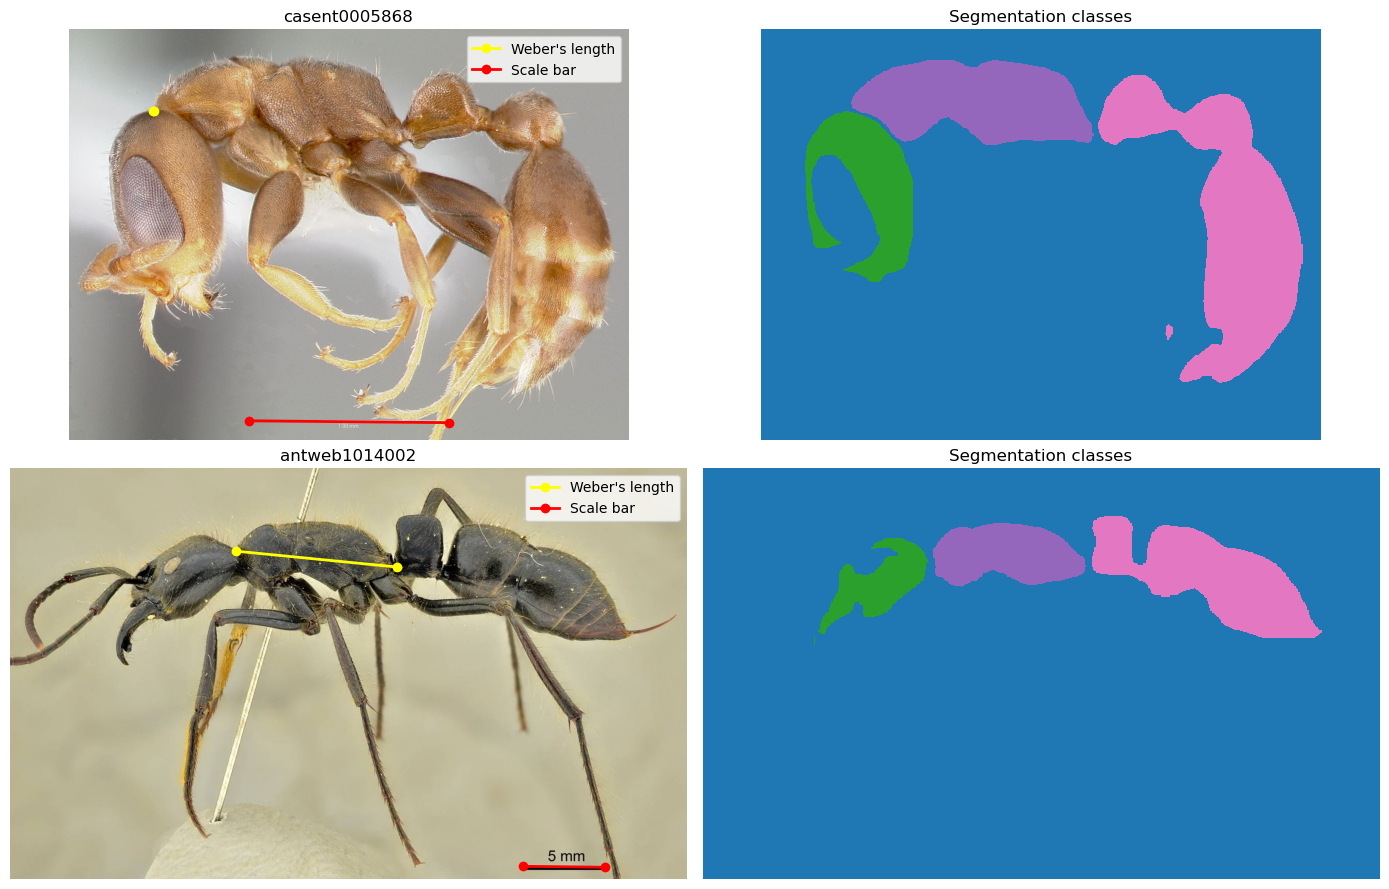

In [6]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

specimens = ["casent0005868", "antweb1014002"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, specimen_id in enumerate(specimens):

    row = df.set_index("specimen_id").loc[specimen_id]
    points = annotations.set_index("specimen_id").loc[specimen_id]

    image = Image.open(ROOT / row["image_path"])
    mask = np.array(Image.open(ROOT / row["mask_path"]))

    height = image.height

    # Original image
    ax = axes[i, 0]
    ax.imshow(image)

    # Convert R coordinates to image coordinates
    for prefix, color, label in [
        ("WL", "yellow", "Weber's length"),
        ("scale", "red", "Scale bar"),
    ]:
        x = [
            points[f"X1_{prefix}"],
            points[f"X2_{prefix}"],
        ]
        y = [
            height - 1 - points[f"Y1_{prefix}"],
            height - 1 - points[f"Y2_{prefix}"],
        ]

        ax.plot(x, y, "o-", color=color,
                linewidth=2, label=label)

    ax.set_title(specimen_id)
    ax.legend()
    ax.axis("off")

    # Identify unique mask values
    if mask.ndim == 2:
        values, encoded = np.unique(
            mask, return_inverse=True
        )
    else:
        values, encoded = np.unique(
            mask.reshape(-1, mask.shape[-1]),
            axis=0, return_inverse=True
        )

    print(f"{specimen_id}: {len(values)} mask values")
    print(values)

    # Colorize the segmentation classes
    colored_mask = encoded.reshape(mask.shape[:2])

    axes[i, 1].imshow(
        colored_mask,
        cmap="tab10",
        interpolation="nearest",
        vmin=0,
        vmax=max(5, len(values) - 1)
    )
    axes[i, 1].set_title("Segmentation classes")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


## 6. Exploring Segmentation Classes

We inspect the unique values in the segmentation masks and visualize each class separately. This helps identify the regions corresponding to the head, thorax, abdomen, and background.

Mask shape: (808, 1330)
Mask dtype: uint8
Unique class values: [0 1 2 3]


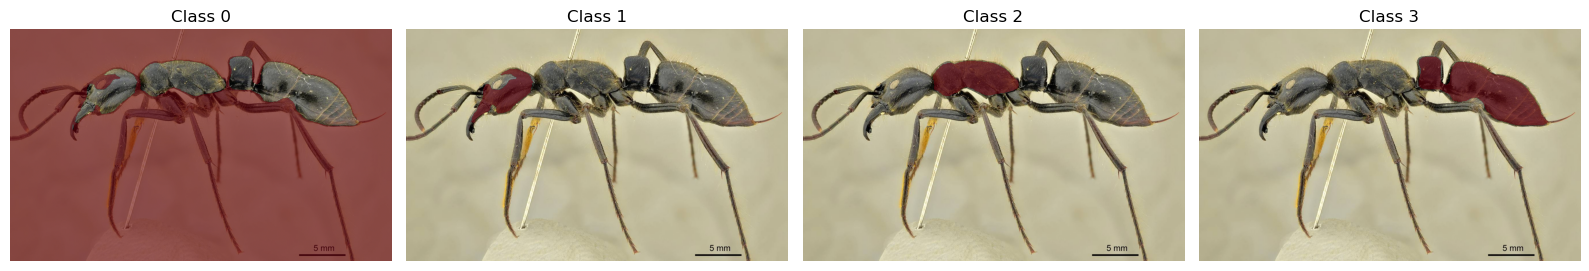

In [7]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

specimen_id = "antweb1014002"

row = df.set_index("specimen_id").loc[specimen_id]

image = np.array(Image.open(ROOT / row["image_path"]))
mask = np.array(Image.open(ROOT / row["mask_path"]))

print("Mask shape:", mask.shape)
print("Mask dtype:", mask.dtype)

# Get all unique segmentation values
if mask.ndim == 2:
    classes = np.unique(mask)
else:
    classes = np.unique(
        mask.reshape(-1, mask.shape[-1]),
        axis=0
    )

print("Unique class values:", classes)

fig, axes = plt.subplots(
    1, len(classes),
    figsize=(4 * len(classes), 4),
    squeeze=False
)

for ax, value in zip(axes[0], classes):

    if mask.ndim == 2:
        region = mask == value
    else:
        region = np.all(mask == value, axis=-1)

    # Overlay the selected class on the original image
    ax.imshow(image)

    overlay = np.ma.masked_where(
        ~region, region.astype(float)
    )

    ax.imshow(
        overlay,
        cmap="Reds",
        alpha=0.6,
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Class {value}")
    ax.axis("off")

plt.tight_layout()
plt.show()


## 7. Extracting the Thorax

We isolate the thorax using segmentation class 2 and crop the image around its bounding box. This produces a thorax-only image and binary mask for further analysis.

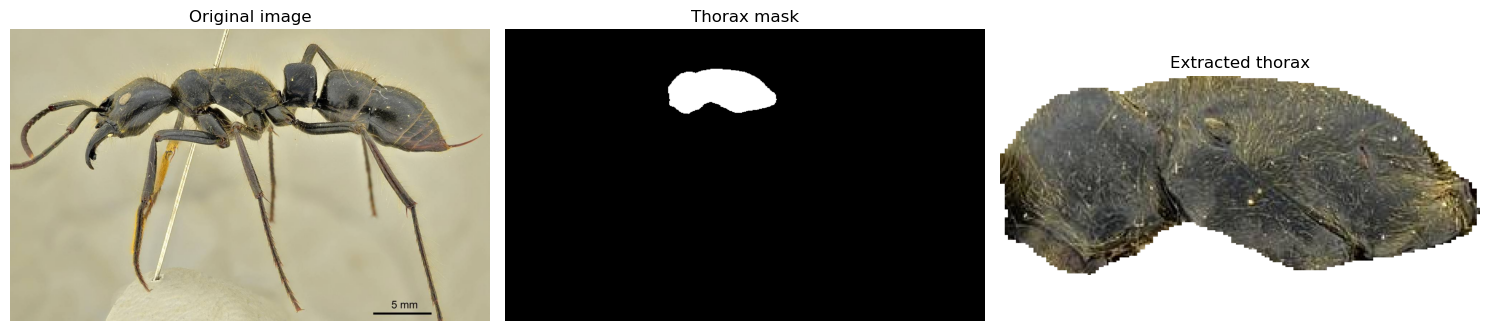

Thorax pixels: 27955
Crop dimensions: (125, 301, 3)


In [8]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

THORAX_CLASS = 2

specimen_id = "antweb1014002"

row = df.set_index("specimen_id").loc[specimen_id]

# Load original image and segmentation
image = np.array(
    Image.open(ROOT / row["image_path"]).convert("RGB")
)

mask = np.array(
    Image.open(ROOT / row["mask_path"])
)

# Check dimensions
assert mask.ndim == 2, "Expected a 2D segmentation mask"
assert image.shape[:2] == mask.shape, "Image/mask size mismatch"

# Extract thorax mask
thorax_mask = mask == THORAX_CLASS

# Check that thorax exists
assert thorax_mask.any(), "No thorax pixels found"

# Keep only thorax pixels (white background)
thorax_image = np.full_like(image, 255)
thorax_image[thorax_mask] = image[thorax_mask]

# Find bounding box
ys, xs = np.where(thorax_mask)

x_min, x_max = xs.min(), xs.max() + 1
y_min, y_max = ys.min(), ys.max() + 1

# Crop thorax
thorax_crop = thorax_image[
    y_min:y_max,
    x_min:x_max
]

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original image")

axes[1].imshow(thorax_mask, cmap="gray")
axes[1].set_title("Thorax mask")

axes[2].imshow(thorax_crop)
axes[2].set_title("Extracted thorax")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Thorax pixels: {thorax_mask.sum()}")
print(f"Crop dimensions: {thorax_crop.shape}")


## 8. Processing All Specimens

We apply the thorax extraction pipeline to all 3,542 specimens. The extracted images, binary masks, and bounding box information are saved for subsequent feature extraction.

In [9]:

from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

THORAX_CLASS = 2

# Load the full dataset (all 3542 specimens)
dataset = pd.read_csv(OUTPUT_DIR / "dataset.csv")

# Output directories
THORAX_IMG_DIR = OUTPUT_DIR / "thorax_images"
THORAX_MASK_DIR = OUTPUT_DIR / "thorax_masks"

THORAX_IMG_DIR.mkdir(parents=True, exist_ok=True)
THORAX_MASK_DIR.mkdir(parents=True, exist_ok=True)

results = []

for i, row in enumerate(dataset.itertuples(index=False), start=1):

    specimen_id = row.specimen_id

    image = np.array(
        Image.open(ROOT / row.image_path).convert("RGB")
    )

    mask = np.array(
        Image.open(ROOT / row.mask_path)
    )

    # Validate segmentation
    if mask.ndim != 2 or mask.shape != image.shape[:2]:
        results.append({
            "specimen_id": specimen_id,
            "status": "invalid_mask"
        })
        continue

    # Extract thorax
    thorax_mask = mask == THORAX_CLASS

    if not thorax_mask.any():
        results.append({
            "specimen_id": specimen_id,
            "status": "missing_thorax"
        })
        continue

    # Bounding box
    ys, xs = np.where(thorax_mask)

    x_min, x_max = xs.min(), xs.max() + 1
    y_min, y_max = ys.min(), ys.max() + 1

    # Crop binary mask
    cropped_mask = thorax_mask[
        y_min:y_max,
        x_min:x_max
    ]

    # Crop original image
    cropped_image = image[
        y_min:y_max,
        x_min:x_max
    ].copy()

    # White background outside thorax
    cropped_image[~cropped_mask] = 255

    # Save paths
    image_out = THORAX_IMG_DIR / f"{specimen_id}.png"
    mask_out = THORAX_MASK_DIR / f"{specimen_id}.png"

    # Save images
    Image.fromarray(cropped_image).save(image_out)

    Image.fromarray(
        cropped_mask.astype(np.uint8) * 255
    ).save(mask_out)

    # Store metadata
    results.append({
        "specimen_id": specimen_id,
        "status": "success",
        "thorax_image_path": image_out.relative_to(ROOT).as_posix(),
        "thorax_mask_path": mask_out.relative_to(ROOT).as_posix(),
        "thorax_area_px": int(thorax_mask.sum()),
        "thorax_width_px": int(x_max - x_min),
        "thorax_height_px": int(y_max - y_min),
        "thorax_xmin": int(x_min),
        "thorax_ymin": int(y_min),
        "thorax_xmax": int(x_max),
        "thorax_ymax": int(y_max),
    })

    if i % 500 == 0:
        print(f"Processed {i}/{len(dataset)}")

# Merge metadata with original dataset
metadata = pd.DataFrame(results)

dataset_thorax = dataset.merge(
    metadata,
    on="specimen_id",
    how="left",
    validate="one_to_one"
)

# Save
dataset_thorax.to_csv(
    OUTPUT_DIR / "dataset_thorax.csv",
    index=False
)

print("\nExtraction summary:")
print(dataset_thorax["status"].value_counts())

print("\nThorax area statistics:")
print(dataset_thorax["thorax_area_px"].describe())


Processed 500/3542
Processed 1000/3542
Processed 1500/3542
Processed 2000/3542
Processed 2500/3542
Processed 3000/3542
Processed 3500/3542

Extraction summary:
status
success    3542
Name: count, dtype: int64

Thorax area statistics:
count      3542.000000
mean      43104.265387
std       17047.447603
min        3052.000000
25%       32000.750000
50%       40497.500000
75%       50413.000000
max      182961.000000
Name: thorax_area_px, dtype: float64


## 9. Extracting Geometric Features

We extract shape descriptors from the thorax masks, including area, perimeter, axis lengths, eccentricity, solidity, and aspect ratio. These features will serve as potential inputs for predicting Weber's length.

In [ ]:

import numpy as np
import pandas as pd
from PIL import Image
from skimage.measure import regionprops, label

# Load dataset with extracted thorax
dataset = pd.read_csv(
    OUTPUT_DIR / "dataset_thorax.csv"
)

features = []

for row in dataset.itertuples(index=False):

    if row.status != "success":
        continue

    # Load binary thorax mask
    mask = np.array(
        Image.open(ROOT / row.thorax_mask_path).convert("L")
    ) > 0

    # Extract geometric properties of the whole thorax
    props = regionprops(mask.astype(np.uint8))[0]

    height, width = mask.shape

    # Count connected components for quality control
    components = label(mask, connectivity=2)
    component_count = components.max()

    features.append({
        "specimen_id": row.specimen_id,
        "area_px": props.area,
        "perimeter_px": props.perimeter,
        "major_axis_px": props.major_axis_length,
        "minor_axis_px": props.minor_axis_length,
        "aspect_ratio": width / height,
        "eccentricity": props.eccentricity,
        "solidity": props.solidity,
        "extent": props.extent,
        "component_count": component_count,
    })

# Create features DataFrame
features_df = pd.DataFrame(features)

# Combine features with existing dataset
dataset_features = dataset.merge(
    features_df,
    on="specimen_id",
    how="left",
    validate="one_to_one"
)

# Save
dataset_features.to_csv(
    OUTPUT_DIR / "dataset_features.csv",
    index=False
)

print(f"Total specimens: {len(dataset_features)}")
print(f"Extracted features: {len(features_df)}")

print("\nFeature statistics:")
print(
    features_df.drop(columns=["specimen_id"])
    .describe()
    .round(3)
)

print("\nConnected components:")
print(features_df["component_count"].value_counts().head(10))


Total specimens: 3542
Extracted features: 3542

Feature statistics:
          area_px  perimeter_px  major_axis_px  minor_axis_px  aspect_ratio  \
count    3542.000      3542.000       3542.000       3542.000      3542.000   
mean    43104.265      1115.723        393.389        151.065         1.984   
std     17047.448       232.543         73.373         35.571         0.394   
min      3052.000       380.894        124.266         43.597         0.686   
25%     32000.750       966.012        347.453        127.124         1.716   
50%     40497.500      1086.194        385.590        147.952         1.960   
75%     50413.000      1217.938        428.878        170.434         2.225   
max    182961.000      2435.411        849.745        436.728         4.043   

       eccentricity  solidity    extent  component_count  
count      3542.000  3542.000  3542.000         3542.000  
mean          0.917     0.854     0.592            1.141  
std           0.041     0.091     0.093    

The characteristics of the thorax masks are generally consistent, but a few values stand out:
- **solidity = 0.143**: very low, potentially indicating an incorrect segmentation.
- **extent = 0.057**: the thorax occupies only 5.7% of its bounding rectangle.
- **component_count = 6**: some masks contain up to six separate regions, which may indicate segmentation errors or artifacts.

## 10. Inspecting Suspicious Segmentations

We visualize specimens with unusually low solidity or multiple disconnected regions. This helps identify potential segmentation errors that could affect the reliability of the extracted features.

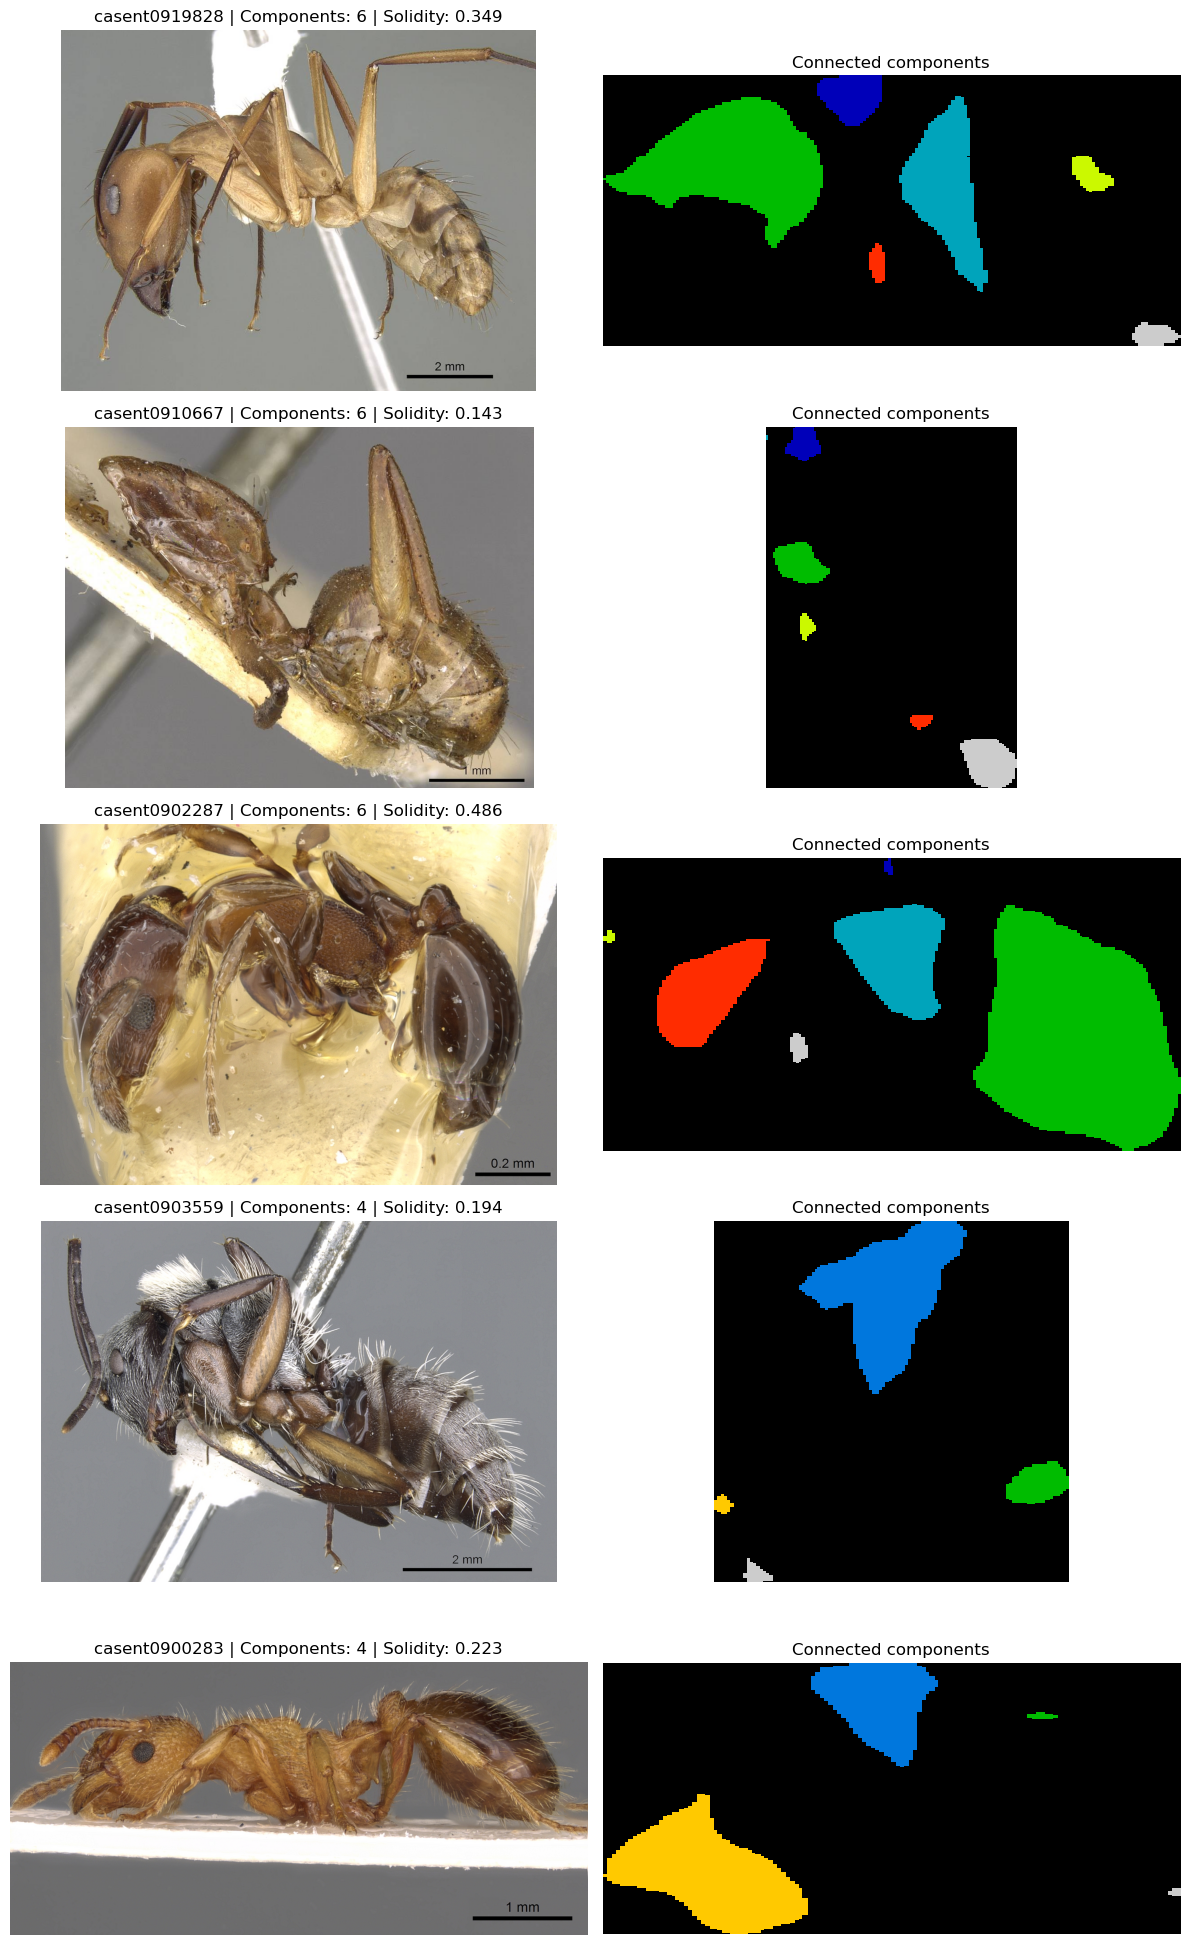

In [11]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.measure import label

# Select suspicious specimens
suspects = pd.concat([
    dataset_features.nlargest(3, "component_count"),
    dataset_features.nsmallest(3, "solidity")
]).drop_duplicates("specimen_id")

fig, axes = plt.subplots(
    len(suspects), 2,
    figsize=(12, 4 * len(suspects)),
    squeeze=False
)

for i, row in enumerate(suspects.itertuples(index=False)):

    image = np.array(
        Image.open(ROOT / row.image_path).convert("RGB")
    )

    mask = np.array(
        Image.open(ROOT / row.thorax_mask_path)
    ) > 0

    # Identify separate connected regions
    components = label(mask, connectivity=2)

    # Display original image
    axes[i, 0].imshow(image)
    axes[i, 0].set_title(
        f"{row.specimen_id} | "
        f"Components: {row.component_count} | "
        f"Solidity: {row.solidity:.3f}"
    )

    # Display segmented components
    axes[i, 1].imshow(
        components,
        cmap="nipy_spectral",
        interpolation="nearest"
    )
    axes[i, 1].set_title("Connected components")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


## 11. Analyzing Connected Components

We calculate the proportion of thorax pixels belonging to the largest connected component. This metric helps distinguish small segmentation artifacts from more significant fragmentation.

In [12]:

from skimage.measure import label

component_stats = []

for row in dataset_features.itertuples(index=False):

    mask = np.array(
        Image.open(ROOT / row.thorax_mask_path)
    ) > 0

    components = label(mask, connectivity=2)

    sizes = np.bincount(
        components.ravel()
    )[1:]  # Exclude background

    largest_ratio = sizes.max() / sizes.sum()

    component_stats.append({
        "specimen_id": row.specimen_id,
        "largest_component_ratio": largest_ratio
    })

component_df = pd.DataFrame(component_stats)

print(component_df["largest_component_ratio"].describe())

print("\nMasks with main component < 95%:")
print(
    (component_df["largest_component_ratio"] < 0.95).sum()
)


count    3542.000000
mean        0.984580
std         0.068730
min         0.382925
25%         1.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: largest_component_ratio, dtype: float64

Masks with main component < 95%:
205


## 12. Defining Quality Control Flags

We flag potentially problematic segmentations based on fragmentation and solidity thresholds. All specimens are retained, while suspicious masks are marked for further inspection.

In [13]:

# Merge quality statistics with our features
dataset_qc = dataset_features.merge(
    component_df,
    on="specimen_id",
    how="left",
    validate="one_to_one"
)

# Quality flags
dataset_qc["fragmented"] = (
    dataset_qc["largest_component_ratio"] < 0.95
)

dataset_qc["low_solidity"] = (
    dataset_qc["solidity"] < 0.5
)

# Flag potentially problematic segmentations
dataset_qc["needs_review"] = (
    dataset_qc["fragmented"]
    | dataset_qc["low_solidity"]
)

# Summary
print("Total specimens:", len(dataset_qc))
print("Fragmented masks:", dataset_qc["fragmented"].sum())
print("Low solidity masks:", dataset_qc["low_solidity"].sum())
print("Masks requiring review:", dataset_qc["needs_review"].sum())
print("Other masks:", (~dataset_qc["needs_review"]).sum())

# Show most suspicious specimens
print("\nMost suspicious specimens:")

print(
    dataset_qc.sort_values(
        "largest_component_ratio"
    )[
        [
            "specimen_id",
            "component_count",
            "largest_component_ratio",
            "solidity",
            "needs_review"
        ]
    ].head(10).to_string(index=False)
)

# Save dataset with quality indicators
dataset_qc.to_csv(
    OUTPUT_DIR / "dataset_features_qc.csv",
    index=False
)


Total specimens: 3542
Fragmented masks: 205
Low solidity masks: 46
Masks requiring review: 208
Other masks: 3334

Most suspicious specimens:
  specimen_id  component_count  largest_component_ratio  solidity  needs_review
casent0104590                3                 0.382925  0.392178          True
casent0903465                4                 0.396335  0.373062          True
casent0910667                6                 0.410236  0.143099          True
casent0908296                3                 0.431685  0.372491          True
casent0102696                2                 0.505129  0.531079          True
casent0601256                2                 0.508894  0.523928          True
casent0903616                3                 0.508932  0.574331          True
casent0067555                2                 0.510032  0.377204          True
casent0281959                2                 0.510173  0.725748          True
casent0191989                2                 0.514123  0.

## 13. Validating Segmentation Quality

We compare randomly selected flagged and unflagged specimens by overlaying their thorax masks on the original images. This provides a qualitative assessment of our quality control criteria.

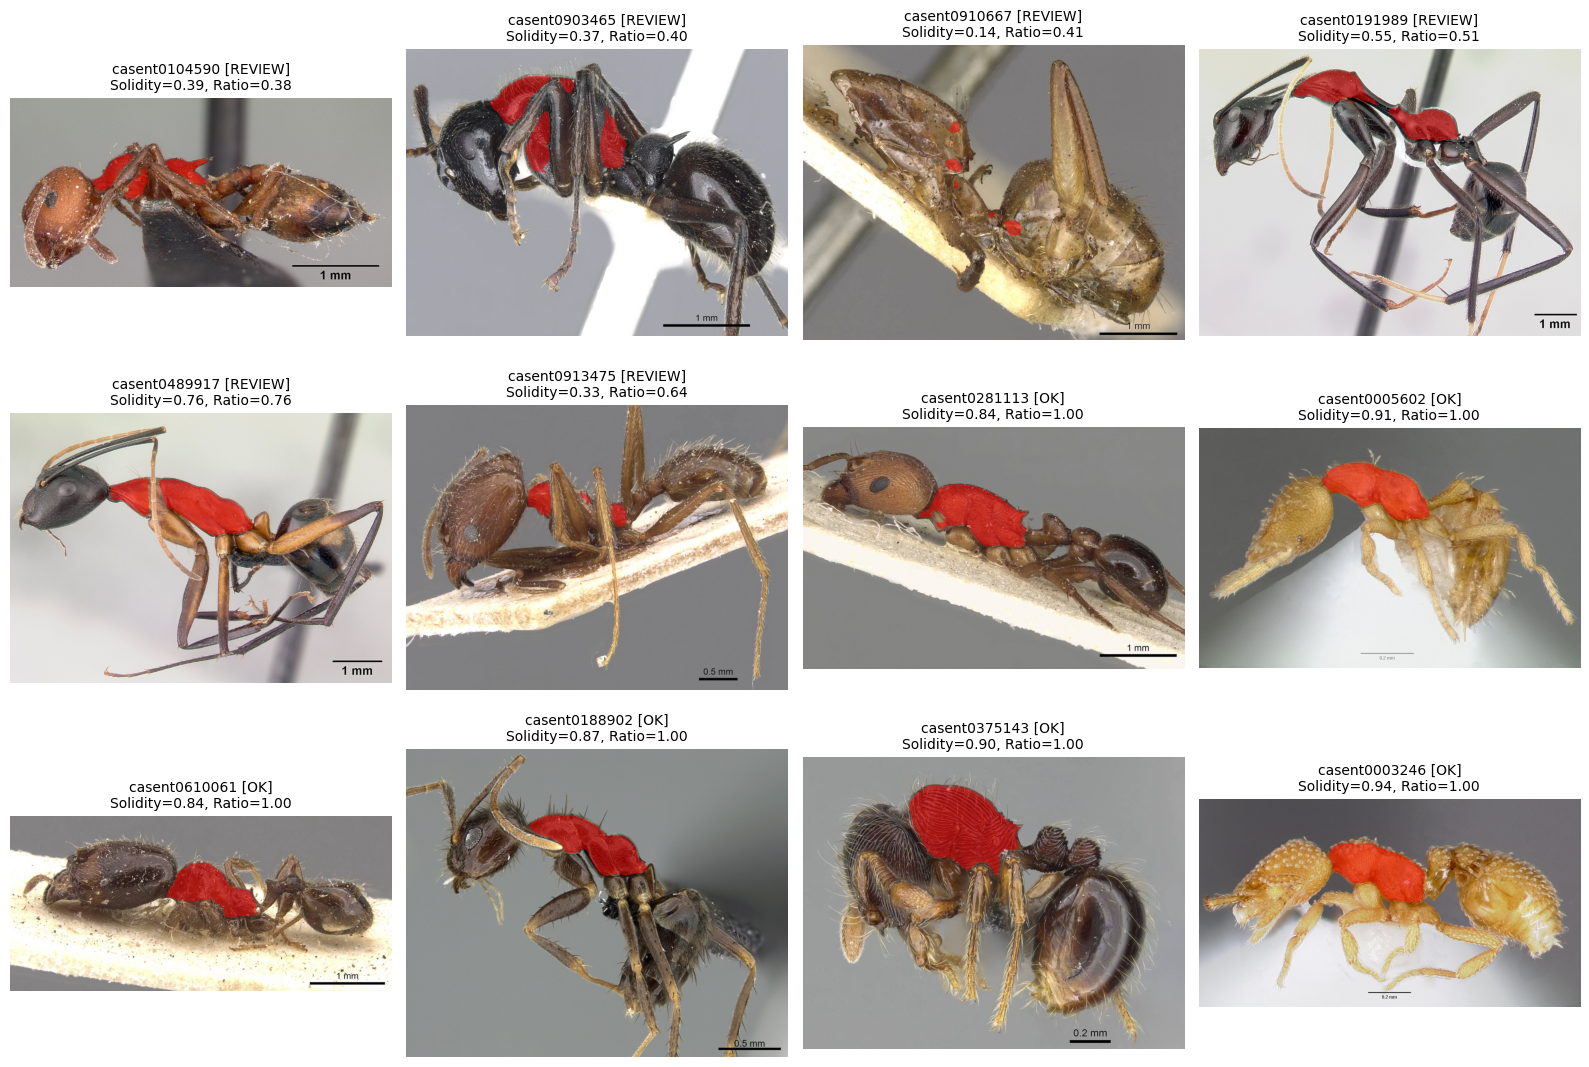

In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# 3 most fragmented masks
worst = dataset_qc.nsmallest(
    3, "largest_component_ratio"
)

# 3 randomly selected suspicious masks
random_suspects = dataset_qc[
    dataset_qc["needs_review"]
    & ~dataset_qc["specimen_id"].isin(worst["specimen_id"])
].sample(n=3, random_state=42)

# 6 randomly selected unflagged masks
random_clean = dataset_qc[
    ~dataset_qc["needs_review"]
].sample(n=6, random_state=42)

samples = pd.concat([
    worst,
    random_suspects,
    random_clean
])

fig, axes = plt.subplots(3, 4, figsize=(16, 11))

for ax, row in zip(axes.flat, samples.itertuples(index=False)):

    image = np.array(
        Image.open(ROOT / row.image_path).convert("RGB")
    )

    mask = np.array(
        Image.open(ROOT / row.mask_path)
    )

    thorax = mask == 2

    # Red overlay on thorax pixels
    overlay = image.copy()

    overlay[thorax] = (
        0.5 * image[thorax]
        + 0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    ax.imshow(overlay)

    status = "REVIEW" if row.needs_review else "OK"

    ax.set_title(
        f"{row.specimen_id} [{status}]\n"
        f"Solidity={row.solidity:.2f}, "
        f"Ratio={row.largest_component_ratio:.2f}",
        fontsize=10
    )

    ax.axis("off")

plt.tight_layout()
plt.show()


## 14. Comparing Manual and Reference Measurements

We compare manually calculated Weber's lengths with the reference measurements. Absolute and relative errors are computed to evaluate agreement and identify potential annotation inconsistencies.

Total comparisons: 500
Mean absolute error (mm): 0.0547
Median relative error (%): 2.43
Measurements differing by >20%: 6


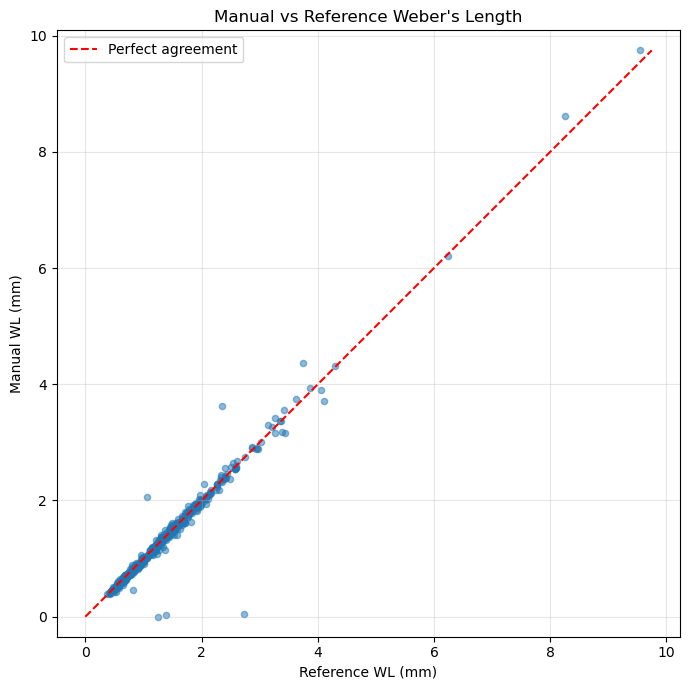


Largest disagreements:
    specimen_id   WL  WL_manual_mm  relative_error_pct
  casent0005868 1.25      0.003258           99.739327
anic32-900057-1 1.38      0.022151           98.394822
  antweb1008903 2.73      0.054814           97.992159
  casent0034340 1.06      2.056981           94.054776
  antweb1008064 2.35      3.626201           54.306408
  antweb1032151 0.82      0.459352           43.981505
  casent0005483 0.53      0.431325           18.618016
  antweb1008062 3.74      4.360280           16.585025
  antweb1041453 1.37      1.151328           15.961481
  casent0005455 0.64      0.552004           13.749397


In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load quality-controlled dataset
dataset = pd.read_csv(
    OUTPUT_DIR / "dataset_features_qc.csv"
)

# Load manual measurements
manual = pd.read_csv(
    OUTPUT_DIR / "dataset_with_manual_wl.csv"
)[["specimen_id", "WL_manual_mm", "scale_px", "WL_px"]]

# Combine datasets
dataset = dataset.merge(
    manual,
    on="specimen_id",
    how="left",
    validate="one_to_one"
)

# Keep specimens with valid manual measurements
comparison = dataset[
    dataset["WL_manual_mm"].notna()
    & (dataset["WL"] > 0)
].copy()

# Calculate relative error
comparison["relative_error_pct"] = (
    abs(comparison["WL_manual_mm"] - comparison["WL"])
    / comparison["WL"]
    * 100
)

# Summary
print("Total comparisons:", len(comparison))
print("Mean absolute error (mm):",
      round(abs(comparison["WL_manual_mm"] - comparison["WL"]).mean(), 4))
print("Median relative error (%):",
      round(comparison["relative_error_pct"].median(), 2))
print("Measurements differing by >20%:",
      (comparison["relative_error_pct"] > 20).sum())

# Scatter plot
plt.figure(figsize=(7, 7))

plt.scatter(
    comparison["WL"],
    comparison["WL_manual_mm"],
    alpha=0.5,
    s=20
)

limit = max(
    comparison["WL"].max(),
    comparison["WL_manual_mm"].max()
)

plt.plot([0, limit], [0, limit], "r--", label="Perfect agreement")

plt.xlabel("Reference WL (mm)")
plt.ylabel("Manual WL (mm)")
plt.title("Manual vs Reference Weber's Length")
plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.tight_layout()
plt.show()

# Show largest disagreements
print("\nLargest disagreements:")

print(
    comparison.nlargest(10, "relative_error_pct")[
        ["specimen_id", "WL", "WL_manual_mm", "relative_error_pct"]
    ].to_string(index=False)
)


## 15. Identifying Annotation Outliers

We identify manual measurements that differ from the reference values by more than 20%. These observations are saved for manual review rather than automatically excluded from the dataset.

In [16]:

# Compute measurement differences
comparison["absolute_error_mm"] = abs(
    comparison["WL_manual_mm"] - comparison["WL"]
)

comparison["needs_annotation_review"] = (
    comparison["relative_error_pct"] > 20
)

# Summary
print("Total annotations:", len(comparison))
print(
    "Mean absolute error (mm):",
    round(comparison["absolute_error_mm"].mean(), 4)
)
print(
    "Median relative error (%):",
    round(comparison["relative_error_pct"].median(), 2)
)
print(
    "Annotations with >20% difference:",
    comparison["needs_annotation_review"].sum()
)

# Inspect suspicious measurements
suspects = comparison[
    comparison["needs_annotation_review"]
].sort_values("relative_error_pct", ascending=False)

print("\nSuspicious annotations:")
print(
    suspects[
        [
            "specimen_id",
            "WL",
            "WL_manual_mm",
            "absolute_error_mm",
            "relative_error_pct",
        ]
    ].to_string(index=False)
)

# Save for manual inspection
suspects.to_csv(
    OUTPUT_DIR / "annotation_review.csv",
    index=False
)


Total annotations: 500
Mean absolute error (mm): 0.0547
Median relative error (%): 2.43
Annotations with >20% difference: 6

Suspicious annotations:
    specimen_id   WL  WL_manual_mm  absolute_error_mm  relative_error_pct
  casent0005868 1.25      0.003258           1.246742           99.739327
anic32-900057-1 1.38      0.022151           1.357849           98.394822
  antweb1008903 2.73      0.054814           2.675186           97.992159
  casent0034340 1.06      2.056981           0.996981           94.054776
  antweb1008064 2.35      3.626201           1.276201           54.306408
  antweb1032151 0.82      0.459352           0.360648           43.981505



## Summary of Data Preparation

### 1. `dataset.csv`

Combines the 3,542 specimens with their morphological measurements, species, and image/mask paths.

| specimen_id | species | TL | HL | EL | WL | image_path | mask_path |
|---|---|---|---|---|---|---|---|
| anic32-015672-1 | Monomorium nanum | 1.99 | 0.48 | 0.15 | 0.55 | data/images/original/anic32-015672-1_p_1.jpg | data/images/mask/anic32-015672-1_p_1.png |

Each row represents one specimen. `WL` is the target variable.

### 2. `dataset_with_manual_wl.csv`

Contains all columns from `dataset.csv`, plus the Weber's Length calculated from manual landmarks and scale bars for 500 specimens.

| Columns from `dataset.csv` | WL_manual_mm | scale_px | WL_px |
|---|---|---|---|
| Same as above | 0.5214 | 393.02 | 409.88 |

- `WL_manual_mm`: Manually annotated Weber's Length converted to millimeters.
- `scale_px`: Scale bar length in pixels.
- `WL_px`: Weber's Length in pixels.

### 3. `dataset_thorax.csv`

Contains all columns from `dataset.csv`, plus information about the extracted thorax regions.

| Columns from `dataset.csv` | status | thorax_image_path | thorax_mask_path |
|---|---|---|---|
| Same as above | success | data/processed/thorax_images/anic32-015672-1.png | data/processed/thorax_masks/anic32-015672-1.png |

**Additional columns:**

| thorax_area_px | thorax_width_px | thorax_height_px | thorax_xmin | thorax_ymin | thorax_xmax | thorax_ymax |
|---|---|---|---|---|---|---|
| 50884 | 438 | 175 | 653 | 150 | 1091 | 325 |

These columns describe the thorax area, bounding box dimensions, and position in the original image.

All 3,542 thorax regions were successfully extracted using segmentation class 2.

### 4. `dataset_features.csv`

Contains all columns from `dataset_thorax.csv`, plus geometric features extracted from the thorax masks.

| Columns from `dataset_thorax.csv` | area_px | perimeter_px | major_axis_px | minor_axis_px |
|---|---|---|---|---|
| Same as above | 50884 | 1177.06 | 447.79 | 151.05 |

**Additional columns:**

| aspect_ratio | eccentricity | solidity | extent | component_count |
|---|---|---|---|---|
| 2.503 | 0.941 | 0.909 | 0.664 | 1 |

These features describe the thorax size, shape, elongation, compactness, and connectivity. They will be used as potential ML inputs.

### 5. `dataset_features_qc.csv`

Contains all columns from `dataset_features.csv`, plus quality control indicators.

| Columns from `dataset_features.csv` | largest_component_ratio | fragmented | low_solidity | needs_review |
|---|---|---|---|---|
| Same as above | 1.0 | False | False | False |

- `largest_component_ratio`: Proportion of thorax pixels belonging to the largest connected component.
- `fragmented`: True if this ratio is below 0.95.
- `low_solidity`: True if solidity is below 0.5.
- `needs_review`: True if either quality criterion is triggered.

We flagged 208 potentially problematic segmentations without removing them.

### 6. `annotation_review.csv`

Contains columns from `dataset_features_qc.csv`, plus manual measurement information and error metrics for specimens with a relative WL difference greater than 20%.

**Example: `casent0005868`**

| Columns from `dataset_features_qc.csv` | WL_manual_mm | scale_px | WL_px |
|---|---|---|---|
| Same specimen data | 0.00326 | 394.02 | 1.28 |

**Additional columns:**

| relative_error_pct | absolute_error_mm | needs_annotation_review |
|---|---|---|
| 99.74 | 1.247 | True |

The reference WL is 1.25 mm, while the manually calculated WL is only 0.00326 mm, suggesting an annotation error.

Suspicious measurements are flagged for manual review rather than automatically removed.

---

In [ ]:
# solidity : 1 forme pleine, < 1 forme irreguliere (trou etc)
# excentricity : 0 forme circulaire, 1 forme allongée
# aspect ratio : > 1 : plus large que haut, < 1 : plus haut que large
# component_count : nombre de composantes connectées dans le masque du thorax